<a href="https://colab.research.google.com/github/vedasrisamarthi-prog/Used-Car-EDA-Project./blob/main/Minor_project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
from google.colab import files
uploaded = files.upload()

Saving AB_NYC_2019.csv.zip to AB_NYC_2019.csv.zip


In [4]:
df = pd.read_csv("AB_NYC_2019.csv.zip")

In [5]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [7]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [8]:
df.shape

(48895, 16)

In [9]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

In [12]:
df.drop('last_review', axis=1, inplace=True)

In [13]:
df.drop(['id', 'name', 'host_id', 'host_name', 'neighbourhood'], axis=1, inplace=True)

In [14]:
df.isnull().sum()

,0
neighbourhood_group,0
latitude,0
longitude,0
room_type,0
price,0
minimum_nights,0
number_of_reviews,0
reviews_per_month,0
calculated_host_listings_count,0
availability_365,0


In [15]:
df.head()

,neighbourhood_group,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,Brooklyn,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0


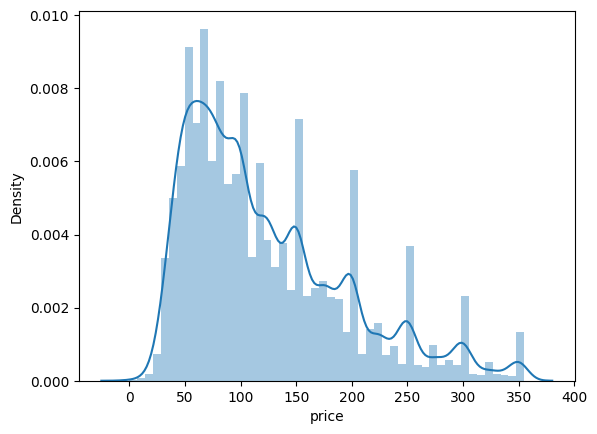

In [21]:
sns.distplot(df['price'])
plt.show()

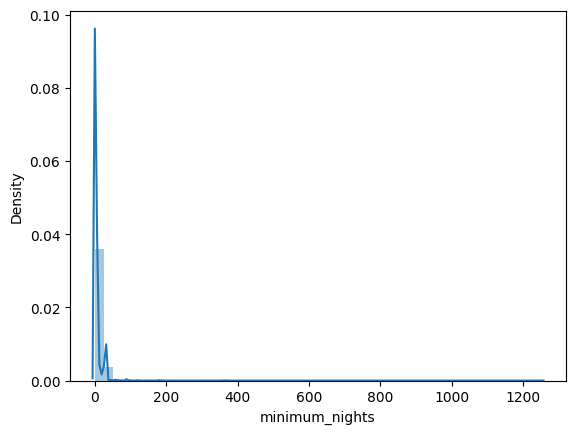

In [22]:
sns.distplot(df['minimum_nights'])
plt.show()

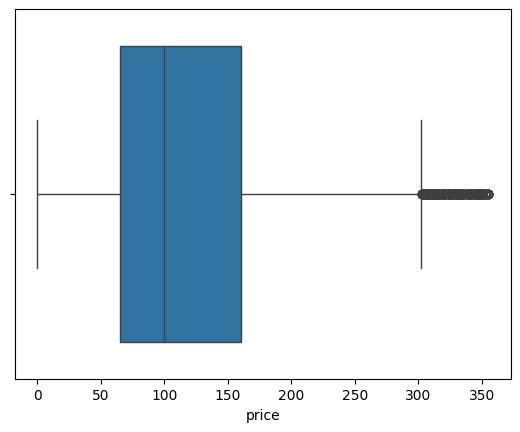

In [23]:
sns.boxplot(x=df['price'])
plt.show()

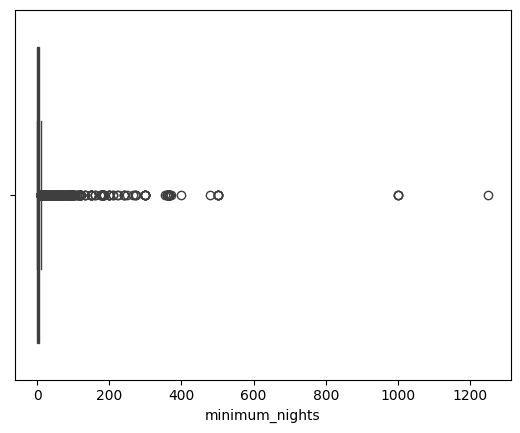

In [24]:
sns.boxplot(x=df['minimum_nights'])
plt.show()

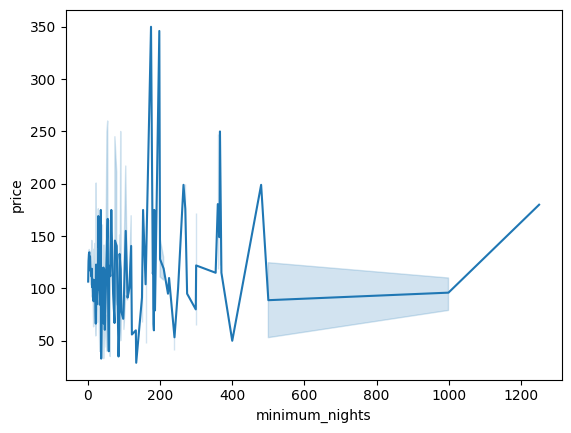

In [25]:
sns.lineplot(x='minimum_nights', y='price', data=df)
plt.show()

In [26]:
upper_bound = df['price'].quantile(0.95)
df = df[df['price'] <= upper_bound]

In [27]:
upper_bound = df['minimum_nights'].quantile(0.95)
df = df[df['minimum_nights'] <= upper_bound]

In [28]:
df.shape

(43666, 10)

In [29]:
df.drop(['id', 'name', 'host_id', 'host_name', 'last_review', 'neighbourhood'], axis=1, inplace=True, errors='ignore')

In [30]:
df = pd.get_dummies(df, columns=['neighbourhood_group', 'room_type'], drop_first=True, dtype=int)

In [31]:
X = df.drop('price', axis=1)
y = df['price']

In [32]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [33]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [34]:
y_pred = model.predict(X_test)

In [35]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.5074975629343677
MAE: 31.880812209843715
MSE: 1771.300440515976
RMSE: 42.08682027091113


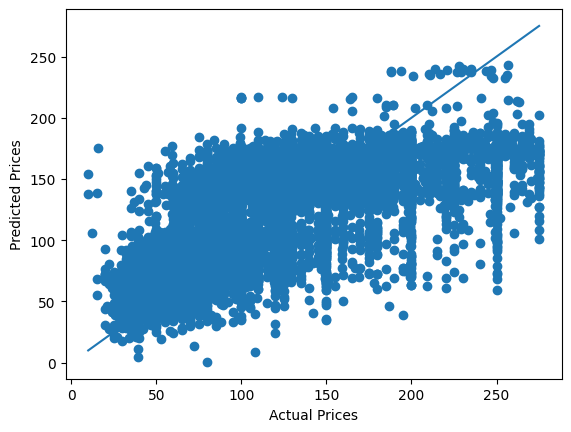

In [36]:
plt.scatter(y_test, y_pred)
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()])
plt.show()

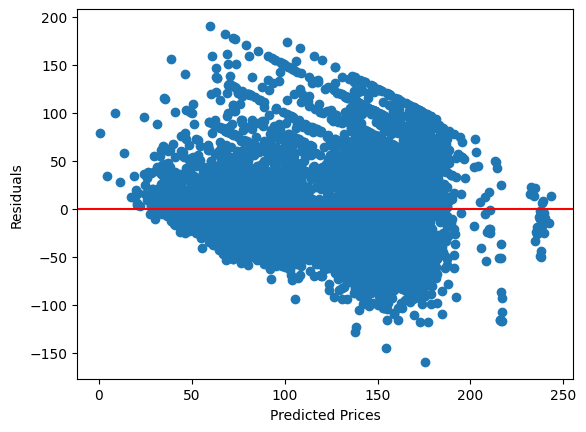

In [37]:
residuals = y_test - y_pred
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red')
plt.xlabel('Predicted Prices')
plt.ylabel('Residuals')
plt.show()

In [38]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: -58.6519359354674
Intercept: -16432.96048821725


In [39]:
r2 = r2_score(y_test, y_pred)
print("R-squared:", r2)

R-squared: 0.5074975629343677


In [40]:
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

Mean Squared Error: 1771.300440515976
